In [9]:
# ============================================================
# Cell 1 — ERA5 climate analysis: setup, loaders, helpers
# Uses the ARCO/Zarr-backed CDS dataset `reanalysis-era5-land-timeseries`
# (one request per pixel for the full year range, run in parallel).
# Subsequent cells use:
#   - phenology    : tidy DataFrame of all breakup/freezeup events
#   - lakes        : dict[site -> GeoDataFrame] in WGS84
#   - download_site_pixels(site, years)      : cached per-pixel ARCO fetch (parallel)
#   - build_era5_dataset(pixel_results)      : assemble pixel files -> (valid_time,lat,lon) Dataset (K)
#   - compute_pixel_weights(lakes_gdf, ds)   : lake polygon -> ERA5 pixel area weights
#   - extract_lake_timeseries(weights, ds)   : weighted-mean t2m per lake (°C)
#   - site_bbox(lakes_gdf)                   : bbox in WGS84
# ============================================================

import time as _time
_t0 = _time.time()
print("Importing libraries...", flush=True)

from pathlib import Path
from typing import Iterable
from concurrent.futures import ThreadPoolExecutor, as_completed
import zipfile
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
from shapely.geometry import box
import cdsapi

print(f"  imports OK ({_time.time()-_t0:.1f}s)", flush=True)

# ---- Paths & constants ----
TIME_SERIES_ROOT = Path(r"C:\Users\nj142\Desktop\Time Series")
SHAPEFILE_ROOT   = Path(r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data")
ERA5_ROOT        = Path(r"E:\planetscope_lake_ice\Data\Input\ERA5 Data")
CDSAPIRC_PATH    = Path(r"D:\planetscope_lake_ice\.cdsapirc")
ERA5_ROOT.mkdir(parents=True, exist_ok=True)
ISOTHERM_MERGED_PATH = ERA5_ROOT / "Figure Inputs" / "isotherm_merged.parquet"

SITES   = ["NS", "YKD", "YF"]
SENSORS = ["PS", "S2"]
SEASONS = ["Breakup", "Freezeup"]
YEARS   = list(range(2019, 2026))

# Months kept per season after download (filters before daily resample/extraction).
# Buffered to cover MAM/SON means, TDD/FDD start dates, and event-date ± uncertainty.
SEASON_MONTHS = {
    "Breakup":  list(range(1, 8)),   # Jan–Jul
    "Freezeup": list(range(8, 13)),  # Aug–Dec
}

ERA5_GRID_RES = 0.1                  # ERA5-Land native resolution (deg)
ALBERS_AK     = "EPSG:3338"          # equal-area, for accurate area-weighted overlaps
WGS84         = "EPSG:4326"
FREEZEUP_MIN_DOY = 240               # DOY cutoff: < 240 = breakup, >= 240 = freezeup

# ---- Phenology loader: 12 CSVs -> one tidy long DataFrame ----
def load_phenology() -> pd.DataFrame:
    """Combine PS+S2 × Breakup+Freezeup × 3 sites into one DataFrame.
    Columns: lake_id, year, site, sensor, season, event_date, error_neg, error_pos, detection_method.
    Rows missing lake_id or year are dropped. `event_date` is NaT when no crossing was detected.
    """
    rows = []
    for sensor in SENSORS:
        for season in SEASONS:
            folder = TIME_SERIES_ROOT / sensor / season
            date_col = f"{season.lower()}_date"
            for csv in folder.glob("*_dates.csv"):
                t0 = _time.time()
                df = pd.read_csv(csv, low_memory=False)
                df = df.dropna(subset=["lake_id", "year"])
                if df.empty:
                    print(f"    {csv.name}: empty, skipping", flush=True)
                    continue
                site = df["dataset"].iloc[0].split("_")[0]
                rows.append(pd.DataFrame({
                    "lake_id":          df["lake_id"].astype(int).values,
                    "year":             df["year"].astype(int).values,
                    "site":             site,
                    "sensor":           sensor,
                    "season":           season,
                    "event_date":       pd.to_datetime(df[date_col], errors="coerce").values,
                    "error_neg":        df.get("error_days_negative").values if "error_days_negative" in df else np.nan,
                    "error_pos":        df.get("error_days_positive").values if "error_days_positive" in df else np.nan,
                    "detection_method": df.get("detection_method").values if "detection_method" in df else None,
                }))
                print(f"    {csv.name}: {len(df):,} rows ({_time.time()-t0:.1f}s)", flush=True)
    return pd.concat(rows, ignore_index=True)

# ---- Shapefile loader: 3 sites, reprojected to WGS84 ----
def load_lakes() -> dict:
    """{site: GeoDataFrame} with columns [lake_id, geometry] in WGS84."""
    out = {}
    for site in SITES:
        t0 = _time.time()
        shp = (SHAPEFILE_ROOT / f"{site} 50x50 km"
               / f"{site} Lakes from ALPOD Shapefile"
               / f"{site}_50x50km_lakes.shp")
        gdf = gpd.read_file(shp).rename(columns={"id": "lake_id"})
        out[site] = gdf[["lake_id", "geometry"]].to_crs(WGS84)
        print(f"    {site}: {len(gdf):,} polygons ({_time.time()-t0:.1f}s)", flush=True)
    return out

def site_bbox(lakes_gdf: gpd.GeoDataFrame) -> tuple:
    """(minx, miny, maxx, maxy) in WGS84 lon/lat."""
    return tuple(lakes_gdf.total_bounds)

# ---- CDS credentials from non-standard .cdsapirc ----
def load_cds_creds(path: Path = CDSAPIRC_PATH) -> tuple:
    creds = {}
    for line in path.read_text().splitlines():
        if ":" in line:
            k, v = line.split(":", 1)
            creds[k.strip().lower()] = v.strip()
    return creds["url"], creds["key"]

# ---- Per-site ERA5-Land pixel centers (snapped to 0.1° grid, with buffer) ----
def site_pixel_centers(lakes_gdf: gpd.GeoDataFrame, pad_deg: float = 0.15) -> list:
    """Return [(lat, lon), ...] of ERA5-Land grid centers covering the site bbox + buffer."""
    minx, miny, maxx, maxy = site_bbox(lakes_gdf)
    lat_lo = np.floor((miny - pad_deg) / ERA5_GRID_RES) * ERA5_GRID_RES
    lat_hi = np.ceil ((maxy + pad_deg) / ERA5_GRID_RES) * ERA5_GRID_RES
    lon_lo = np.floor((minx - pad_deg) / ERA5_GRID_RES) * ERA5_GRID_RES
    lon_hi = np.ceil ((maxx + pad_deg) / ERA5_GRID_RES) * ERA5_GRID_RES
    lats = np.round(np.arange(lat_lo, lat_hi + 1e-9, ERA5_GRID_RES), 2)
    lons = np.round(np.arange(lon_lo, lon_hi + 1e-9, ERA5_GRID_RES), 2)
    return [(float(la), float(lo)) for la in lats for lo in lons]

# ---- ARCO timeseries download: one pixel × full year range × all years ----
# CDS rejects new submits when the per-dataset queue cap is hit ("Number queued
# requests for this dataset is temporarily limited"). The 400 is transient: retry
# with backoff so a momentarily full queue doesn't drop the pixel from the grid.
_CDS_QUEUE_FULL_HINTS = ("queued requests", "rejected", "temporarily limited")

def download_pixel_timeseries(site: str, lat: float, lon: float,
                              years: Iterable[int],
                              max_attempts: int = 5) -> Path:
    out_dir = ERA5_ROOT / site / "pixels"
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / f"{site}_lat{lat:+07.2f}_lon{lon:+07.2f}_t2m.nc"
    if out_path.exists() and out_path.stat().st_size > 0:
        return out_path

    zip_path = out_path.with_suffix(".zip")
    yrs = list(years)
    date_range = f"{min(yrs)}-01-01/{max(yrs)}-12-31"
    url, key = load_cds_creds()
    request = {
        "variable":    ["2m_temperature"],
        "location":    {"longitude": float(lon), "latitude": float(lat)},
        "date":        [date_range],
        "data_format": "netcdf",
    }

    for attempt in range(1, max_attempts + 1):
        try:
            cdsapi.Client(url=url, key=key, quiet=True).retrieve(
                "reanalysis-era5-land-timeseries", request, str(zip_path),
            )
            # Unzip if CDS returned a ZIP archive
            magic = zip_path.read_bytes()[:4]
            if magic == b'PK\x03\x04':
                with zipfile.ZipFile(zip_path) as zf:
                    nc_names = [n for n in zf.namelist() if n.endswith(".nc")]
                    if not nc_names:
                        raise ValueError(f"ZIP contains no .nc files: {zf.namelist()}")
                    with zf.open(nc_names[0]) as src, open(out_path, "wb") as dst:
                        dst.write(src.read())
                zip_path.unlink()
            else:
                # Already a plain NetCDF — just rename
                zip_path.rename(out_path)
            return out_path
        except Exception as e:
            msg = str(e).lower()
            if any(h in msg for h in _CDS_QUEUE_FULL_HINTS) and attempt < max_attempts:
                wait = 30 * (2 ** (attempt - 1))
                print(f"    [retry {attempt}/{max_attempts}] CDS queue full for "
                      f"({lat:+.2f},{lon:+.2f}); sleeping {wait}s...", flush=True)
                _time.sleep(wait)
                continue
            # Clean up partial files before re-raising
            for p in (zip_path, out_path):
                if p.exists(): p.unlink()
            raise

def download_site_pixels(site: str, years: Iterable[int],
                         max_workers: int = 4) -> list:
    """Download all ERA5 pixel timeseries covering a site, in parallel.
    Returns [(lat, lon, Path), ...] for successful pixels.

    Default `max_workers=2` keeps the per-dataset CDS queue from overflowing.
    Going higher (e.g. 8) regularly trips the queue limit on
    `reanalysis-era5-land-timeseries`; the retry loop in
    download_pixel_timeseries can absorb brief spikes but won't save you from
    sustained over-submission.
    """
    pixels = site_pixel_centers(lakes[site])
    results: list = [None] * len(pixels)
    t0 = _time.time()
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        futs = {ex.submit(download_pixel_timeseries, site, la, lo, years): (i, la, lo)
                for i, (la, lo) in enumerate(pixels)}
        for n, f in enumerate(as_completed(futs), 1):
            i, la, lo = futs[f]
            try:
                results[i] = (la, lo, f.result())
            except Exception as e:
                print(f"    ! [{site}] pixel ({la:+.2f},{lo:+.2f}) failed: {type(e).__name__}: {e}", flush=True)
                results[i] = None
            if n % 5 == 0 or n == len(futs):
                rate = n / max(1e-3, _time.time()-t0)
                print(f"    [{site}] {n}/{len(futs)} pixels  ({rate:.1f}/s, "
                      f"elapsed {_time.time()-t0:.0f}s)", flush=True)
    return [r for r in results if r is not None]

# ---- Combine per-pixel timeseries files into one (valid_time, lat, lon) Dataset ----
def build_era5_dataset(pixel_results: list) -> xr.Dataset:
    """Returns Dataset with variable `t2m` (Kelvin), dims (valid_time, latitude, longitude).
    Defensive about the per-pixel file's variable / time-dim naming.
    """
    print(f"    assembling {len(pixel_results)} pixel files into Dataset...", flush=True)
    t0 = _time.time()
    arrays = []
    for la, lo, path in pixel_results:
        ds = xr.open_dataset(path)
        var_name = next((v for v in ds.data_vars
                         if v in ("t2m", "2m_temperature") or "temperature" in v.lower()),
                        list(ds.data_vars)[0])
        da = ds[var_name].rename("t2m")
        time_dim = next((d for d in da.dims if "time" in d.lower()), da.dims[0])
        if time_dim != "valid_time":
            da = da.rename({time_dim: "valid_time"})
        for c in ("latitude", "longitude", "lat", "lon"):
            if c in da.coords and c not in da.dims:
                da = da.drop_vars(c)
        da = da.expand_dims(latitude=[la], longitude=[lo])
        arrays.append(da)
    combined = xr.combine_by_coords(arrays)
    if isinstance(combined, xr.DataArray):
        combined = combined.to_dataset()
    print(f"    Dataset built ({_time.time()-t0:.1f}s, dims={dict(combined.sizes)})", flush=True)
    return combined

# ---- Lake polygon -> ERA5 pixel area weights ----
def compute_pixel_weights(lakes_gdf: gpd.GeoDataFrame,
                          era5_ds: xr.Dataset) -> pd.DataFrame:
    """For each lake, fractional area overlap with each ERA5 grid cell.
    Areas computed in Alaska Albers (equal-area). Weights for a given lake
    sum to <=1 (==1 when the lake is fully inside the bbox).
    Returns: [lake_id, lat_idx, lon_idx, weight].
    """
    print(f"    computing pixel weights for {len(lakes_gdf):,} lakes...", flush=True)
    t0 = _time.time()
    lats = era5_ds["latitude"].values
    lons = era5_ds["longitude"].values
    dlat = abs(float(lats[1] - lats[0])) if len(lats) > 1 else ERA5_GRID_RES
    dlon = abs(float(lons[1] - lons[0])) if len(lons) > 1 else ERA5_GRID_RES

    pixels = gpd.GeoDataFrame(
        [{"lat_idx": i, "lon_idx": j,
          "geometry": box(lon - dlon/2, lat - dlat/2, lon + dlon/2, lat + dlat/2)}
         for i, lat in enumerate(lats) for j, lon in enumerate(lons)],
        crs=WGS84,
    ).to_crs(ALBERS_AK)

    lk = lakes_gdf.to_crs(ALBERS_AK)[["lake_id", "geometry"]].copy()
    lk["lake_area"] = lk.geometry.area

    inter = gpd.overlay(lk, pixels, how="intersection")
    inter["weight"] = inter.geometry.area / inter["lake_area"]
    out = inter[["lake_id", "lat_idx", "lon_idx", "weight"]].reset_index(drop=True)
    print(f"    weights: {len(out):,} (lake,pixel) pairs ({_time.time()-t0:.1f}s)", flush=True)
    return out

# ---- Weighted-mean t2m time series per lake (°C) ----
def extract_lake_timeseries(weights_df: pd.DataFrame, era5_ds: xr.Dataset,
                            var: str = "t2m") -> pd.DataFrame:
    """Long DataFrame [lake_id, time, t2m_C]. K -> °C."""
    print(f"    extracting per-lake t2m series...", flush=True)
    t0 = _time.time()
    da = era5_ds[var]
    time_coord = "valid_time" if "valid_time" in da.coords else "time"
    time = pd.to_datetime(da[time_coord].values)
    arr = da.values - 273.15

    out = []
    n_lakes = weights_df["lake_id"].nunique()
    for n, (lake_id, g) in enumerate(weights_df.groupby("lake_id"), 1):
        w = g["weight"].values
        i = g["lat_idx"].astype(int).values
        j = g["lon_idx"].astype(int).values
        ts = (arr[:, i, j] * w).sum(axis=1) / w.sum()
        out.append(pd.DataFrame({"lake_id": int(lake_id), "time": time, "t2m_C": ts}))
        if n % 1000 == 0:
            print(f"      {n}/{n_lakes} lakes done", flush=True)
    df = pd.concat(out, ignore_index=True)
    print(f"    extracted: {len(df):,} rows ({_time.time()-t0:.1f}s)", flush=True)
    return df

# ---- Wire up the small/cheap loads now ----
print("\nLoading phenology CSVs...", flush=True)
phenology = load_phenology()
print(f"\nLoading lake shapefiles...", flush=True)
lakes     = load_lakes()

print(f"\n=== SUMMARY ({_time.time()-_t0:.1f}s total) ===", flush=True)
print(f"Phenology: {len(phenology):,} rows  "
      f"(sites={sorted(phenology['site'].unique().tolist())}, "
      f"sensors={sorted(phenology['sensor'].unique().tolist())}, "
      f"years={sorted(phenology['year'].unique().tolist())})")
for s in SITES:
    n_pix = len(site_pixel_centers(lakes[s]))
    print(f"  {s}: {len(lakes[s]):,} lakes, "
          f"bbox={tuple(round(x,3) for x in site_bbox(lakes[s]))}, "
          f"{n_pix} ERA5 pixels to download")

    YKD_breakup_dates.csv: 58,331 rows (0.6s)
    NS_freezeup_dates.csv: 39,858 rows (0.2s)
    YF_freezeup_dates.csv: 13,006 rows (0.1s)
    YKD_freezeup_dates.csv: 58,331 rows (0.3s)

Loading lake shapefiles...
    NS: 5,694 polygons (17.4s)
    YKD: 8,333 polygons (0.3s)
    YF: 1,858 polygons (0.1s)

=== SUMMARY (21.4s total) ===
Phenology: 444,404 rows  (sites=['NS', 'YF', 'YKD'], sensors=['PS', 'S2'], years=[2019, 2020, 2021, 2022, 2023, 2024, 2025])
  NS: 5,694 lakes, bbox=(-155.913, 70.352, -154.559, 70.801), 162 ERA5 pixels to download
  YKD: 8,333 lakes, bbox=(-162.376, 60.946, -161.441, 61.395), 150 ERA5 pixels to download
  YF: 1,858 lakes, bbox=(-146.33, 66.459, -145.208, 66.907), 144 ERA5 pixels to download


In [10]:
# ============================================================
# Cell 2 — Build per-lake daily T2m panels (site × season)
# Heavy: triggers parallel ARCO pixel downloads + per-lake extraction.
# Caches a parquet per (site, season) so re-runs are fast.
# Per-pixel .nc files are also cached and reused across both seasons.
# Produces:
#   t2m_daily : DataFrame [lake_id, time, t2m_C, site, season]
# ============================================================

def filter_to_season(era5_ds: xr.Dataset, season: str) -> xr.Dataset:
    """Subset the Dataset to the months relevant for this season."""
    tcoord = "valid_time" if "valid_time" in era5_ds.coords else "time"
    months = SEASON_MONTHS[season]
    return era5_ds.sel({tcoord: era5_ds[tcoord].dt.month.isin(months)})

def hourly_to_daily(era5_ds: xr.Dataset, var: str = "t2m") -> xr.Dataset:
    """Hourly -> calendar-day mean (UTC). Cuts memory ~24x before extraction."""
    tcoord = "valid_time" if "valid_time" in era5_ds.coords else "time"
    return era5_ds[[var]].resample({tcoord: "1D"}).mean()

def build_t2m_panel(site: str, season: str, full_ds: xr.Dataset) -> pd.DataFrame:
    """Filter season -> daily mean -> weighted per-lake series. Tagged with site/season."""
    print(f"  [{site} {season}] filtering to season months...", flush=True)
    season_ds = filter_to_season(full_ds, season)
    print(f"  [{site} {season}] resampling hourly -> daily (vars={list(season_ds.data_vars)}, "
          f"dims={dict(season_ds.sizes)})...", flush=True)
    daily = hourly_to_daily(season_ds)
    daily.load()  # force compute
    weights = compute_pixel_weights(lakes[site], daily)
    df = extract_lake_timeseries(weights, daily)
    df["site"] = site
    df["season"] = season
    return df

def get_or_build_panel(site: str, season: str, full_ds_factory) -> pd.DataFrame:
    """Parquet-cached. `full_ds_factory()` is lazily called only on cache miss."""
    cache = ERA5_ROOT / site / season / f"{site}_{season}_daily_t2m.parquet"
    cache.parent.mkdir(parents=True, exist_ok=True)
    if cache.exists():
        print(f"  [{site} {season}] cache hit -> {cache.name}", flush=True)
        return pd.read_parquet(cache)
    df = build_t2m_panel(site, season, full_ds_factory())
    df.to_parquet(cache, index=False)
    print(f"  [{site} {season}] cached -> {cache.name}", flush=True)
    return df

import time as _time
_t0 = _time.time()
panels = []
for site in SITES:
    print(f"\n=== [{site}] ({_time.time()-_t0:.0f}s elapsed) ===", flush=True)
    seasons_needed = [s for s in SEASONS
                      if not (ERA5_ROOT / site / s / f"{site}_{s}_daily_t2m.parquet").exists()]
    if seasons_needed:
        n_pix = len(site_pixel_centers(lakes[site]))
        # 2 workers is the sweet spot for `reanalysis-era5-land-timeseries` —
        # higher overflows the per-dataset CDS queue and the 400s start dropping pixels.
        print(f"  downloading {n_pix} ERA5 pixel timeseries (parallel, 4 workers)...", flush=True)
        pixel_results = download_site_pixels(site, YEARS, max_workers=4)
        # Refuse to cache a partial grid: a parquet built from a truncated set of
        # pixels will silently misrepresent boundary lakes on every later cache hit.
        if len(pixel_results) != n_pix:
            raise RuntimeError(
                f"[{site}] only {len(pixel_results)}/{n_pix} pixels downloaded successfully; "
                f"refusing to build incomplete dataset. Re-run the cell — pixel .nc files "
                f"already on disk will be reused, so only the failed pixels will retry."
            )
        full_ds = build_era5_dataset(pixel_results)
        factory = lambda ds=full_ds: ds
    else:
        print(f"  all season parquets cached, skipping downloads", flush=True)
        factory = lambda: None

    for season in SEASONS:
        df = get_or_build_panel(site, season, factory)
        print(f"  [{site} {season}] {len(df):,} rows, "
              f"{df['lake_id'].nunique():,} lakes, "
              f"{df['time'].min().date()} → {df['time'].max().date()}", flush=True)
        panels.append(df)

print(f"\nConcatenating panels...", flush=True)
t2m_daily = pd.concat(panels, ignore_index=True)

print(f"\nConcatenating panels...", flush=True)
t2m_daily = pd.concat(panels, ignore_index=True)
# Season panels carry empty off-season days from the daily resample; drop them so
# drop_duplicates in the window metrics doesn't keep an empty copy over the real one.
t2m_daily = t2m_daily.dropna(subset=["t2m_C"]).reset_index(drop=True)

expected = sum(len(lakes[s]) for s in SITES) * len(SEASONS)
got = t2m_daily.groupby(["site","season"])["lake_id"].nunique().sum()
print(f"\n=== DONE ({_time.time()-_t0:.0f}s total) ===")
print(f"t2m_daily total: {len(t2m_daily):,} rows")
print(f"lake×season coverage: {got} / {expected}")


=== [NS] (0s elapsed) ===
  all season parquets cached, skipping downloads
  [NS Breakup] cache hit -> NS_Breakup_daily_t2m.parquet
  [NS Breakup] 13,688,376 rows, 5,694 lakes, 2019-01-01 → 2025-07-31
  [NS Freezeup] cache hit -> NS_Freezeup_daily_t2m.parquet
  [NS Freezeup] 13,352,430 rows, 5,694 lakes, 2019-08-01 → 2025-12-31

=== [YKD] (2s elapsed) ===
  all season parquets cached, skipping downloads
  [YKD Breakup] cache hit -> YKD_Breakup_daily_t2m.parquet
  [YKD Breakup] 20,032,532 rows, 8,333 lakes, 2019-01-01 → 2025-07-31
  [YKD Freezeup] cache hit -> YKD_Freezeup_daily_t2m.parquet
  [YKD Freezeup] 19,540,885 rows, 8,333 lakes, 2019-08-01 → 2025-12-31

=== [YF] (4s elapsed) ===
  all season parquets cached, skipping downloads
  [YF Breakup] cache hit -> YF_Breakup_daily_t2m.parquet
  [YF Breakup] 4,466,632 rows, 1,858 lakes, 2019-01-01 → 2025-07-31
  [YF Freezeup] cache hit -> YF_Freezeup_daily_t2m.parquet
  [YF Freezeup] 4,357,010 rows, 1,858 lakes, 2019-08-01 → 2025-12-31

C

In [11]:
# ============================================================
# Cell 3 - Analysis helpers (used by all metric cells below)
# Defines:
#   - merge_with_phenology(metric_df, col)  : inner-join metric with event dates,
#                                             adds `event_doy`. Drops phenology rows
#                                             whose event_date falls outside the season's
#                                             valid month window (e.g. a "Freezeup"
#                                             tagged with a July date).
#   - compute_event_windows(phen_df, n_days=30)
#                                           : per-(site, season) DOY window of `n_days`
#                                             ending one day before the earliest event
#                                             observed across all years/lakes/sensors
#                                             at that site. Same window for every
#                                             (lake, year, sensor) at that site.
#   - plot_correlation_grid(merged, col, label, season)
#                                           : 3x2 (site x sensor) scatter + linear fit + Pearson r
# ============================================================

import matplotlib.pyplot as plt
from scipy.stats import pearsonr

def _filter_valid_season(df: pd.DataFrame) -> pd.DataFrame:
    """Drop rows where the labeled season is inconsistent with the event date.
    Breakup events must occur Jan-Jul of the labeled year. Freezeup events must
    occur Aug-Dec of the labeled year, OR Jan-Jun of the next year (for events
    that crossed the calendar boundary). Anything else (e.g. "Freezeup" with
    event_date in July) is dropped as a mislabel.
    """
    ed = pd.to_datetime(df["event_date"])
    em, ey, yr = ed.dt.month, ed.dt.year, df["year"]
    ed_doy = ed.dt.dayofyear
    breakup_ok  = (df["season"] == "Breakup")  & (ed_doy < FREEZEUP_MIN_DOY) & (ey == yr)
    # Freezeup: same calendar year requires DOY >= FREEZEUP_MIN_DOY (≥ 240);
    # events that spill into Jan-Jun of the NEXT year are always valid freezeup.
    freezeup_ok = (df["season"] == "Freezeup") & (
        ((ed_doy >= FREEZEUP_MIN_DOY) & (ey == yr)) |
        ((em <= 6) & (ey == yr + 1))
    )
    return df[breakup_ok | freezeup_ok].copy()

def merge_with_phenology(metric_df: pd.DataFrame, metric_col: str) -> pd.DataFrame:
    """Inner-join a per-(lake, year, site, season) metric with phenology event dates.
    Phenology rows whose event_date doesn't match the labeled season's month range
    are dropped (see _filter_valid_season). Adds `event_doy` (DOY of event_date).
    Freezeup events that crossed into the next calendar year get +365 so the
    predictor stays monotonic.
    """
    df = phenology.merge(metric_df, on=["lake_id", "year", "site", "season"], how="inner")
    df["event_date"] = pd.to_datetime(df["event_date"])
    df = df.dropna(subset=["event_date"])
    df = _filter_valid_season(df)
    df["event_doy"] = df["event_date"].dt.dayofyear.astype(float)
    cross = (df["season"] == "Freezeup") & (df["event_date"].dt.year > df["year"])
    df.loc[cross, "event_doy"] += 365
    return df.dropna(subset=[metric_col, "event_doy"])

def compute_event_windows(phen_df: pd.DataFrame, n_days: int = 30) -> dict:
    """For each (site, season), find the earliest observed event DOY across
    every year/lake/sensor (after dropping mislabeled events). Returns
    dict[(site, season)] -> (start_doy, end_doy), an `n_days`-long DOY window
    ending one day before that earliest event.

    Same window is used for every (lake, year, sensor) at that site/season,
    so the resulting metric is independent of the phenology dates being predicted.
    """
    df = phen_df.dropna(subset=["event_date"]).copy()
    df["event_date"] = pd.to_datetime(df["event_date"])
    df = _filter_valid_season(df)
    df["event_doy"] = df["event_date"].dt.dayofyear.astype(float)
    cross = (df["season"] == "Freezeup") & (df["event_date"].dt.year > df["year"])
    df.loc[cross, "event_doy"] += 365
    windows = {}
    for (site, season), g in df.groupby(["site", "season"]):
        earliest = int(g["event_doy"].min())
        windows[(site, season)] = (earliest - n_days, earliest - 1)
        print(f"  [{site} {season}] earliest event DOY = {earliest}, "
              f"window = DOY {earliest - n_days}-{earliest - 1} "
              f"({n_days} days, n_events={len(g):,})")
    return windows

def plot_correlation_grid(merged_df: pd.DataFrame, metric_col: str,
                          metric_label: str, season: str,
                          ylabel: str = None) -> None:
    """3x2 grid (rows=sites, cols=sensors) of scatter + linear fit + Pearson r/p.
    One figure per call (one season). Each panel shows lakes x years for that
    site+sensor combination.
    """
    print(f"  plotting {metric_label} x {season}...", flush=True)
    sub_all = merged_df[merged_df["season"] == season]
    fig, axes = plt.subplots(3, 2, figsize=(10, 11), sharey=False)
    for i, site in enumerate(SITES):
        for j, sensor in enumerate(SENSORS):
            ax = axes[i, j]
            sub = sub_all[(sub_all["site"] == site) & (sub_all["sensor"] == sensor)]
            if len(sub) >= 3:
                ax.scatter(sub[metric_col], sub["event_doy"],
                           alpha=0.25, s=8, edgecolor="none")
                try:
                    if sub[metric_col].nunique() < 2:
                        raise ValueError("zero variance in predictor")
                    r, p = pearsonr(sub[metric_col], sub["event_doy"])
                    slope, intercept = np.polyfit(sub[metric_col], sub["event_doy"], 1)
                    xs = np.array([sub[metric_col].min(), sub[metric_col].max()])
                    ax.plot(xs, slope*xs + intercept, "r-", lw=1.2)
                    ax.text(0.04, 0.96, f"r = {r:.2f}\np = {p:.2g}\nn = {len(sub):,}",
                            transform=ax.transAxes, va="top", fontsize=9,
                            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="0.7", alpha=0.9))
                    print(f"    {site}  {sensor}: r={r:+.2f}  p={p:.2g}  n={len(sub):,}", flush=True)
                except Exception as fit_err:
                    ax.text(0.04, 0.96, f"fit failed\n{fit_err}",
                            transform=ax.transAxes, va="top", fontsize=8, color="red")
                    print(f"    {site}  {sensor}: fit failed ({fit_err})", flush=True)
            else:
                ax.text(0.5, 0.5, f"n = {len(sub)}", ha="center", va="center",
                        transform=ax.transAxes)
                print(f"    {site}  {sensor}: n={len(sub)} (too few for fit)", flush=True)
            ax.set_title(f"{site} - {sensor}", fontsize=10)
            if i == 2: ax.set_xlabel(metric_label)
            if j == 0: ax.set_ylabel(ylabel or f"{season} DOY")
    fig.suptitle(f"{metric_label}  vs  {season} date", fontsize=13)
    fig.tight_layout()
    plt.show()

print("Analysis helpers defined: merge_with_phenology, compute_event_windows, plot_correlation_grid")


Analysis helpers defined: merge_with_phenology, compute_event_windows, plot_correlation_grid


Computing 0°C isotherm DOY per lake-year...
  [NS Breakup] 5,694 lakes × 7 years (2.4s)
  [NS Freezeup] 5,694 lakes × 7 years (1.7s)
  [YF Breakup] 1,858 lakes × 7 years (0.7s)
  [YF Freezeup] 1,858 lakes × 7 years (0.5s)
  [YKD Breakup] 8,329 lakes × 7 years (3.7s)
  [YKD Freezeup] 8,329 lakes × 7 years (2.6s)
  -> 222,334 rows
Merging with phenology...
  -> 356,639 rows after join
  plotting Spring 0°C isotherm DOY x Breakup...
    NS  PS: r=+0.38  p=0  n=32,636
    NS  S2: r=+0.31  p=0  n=39,582
    YKD  PS: r=+0.37  p=0  n=55,626
    YKD  S2: r=+0.45  p=0  n=57,573
    YF  PS: r=+0.18  p=9.7e-89  n=12,664
    YF  S2: r=+0.24  p=9.3e-166  n=12,889


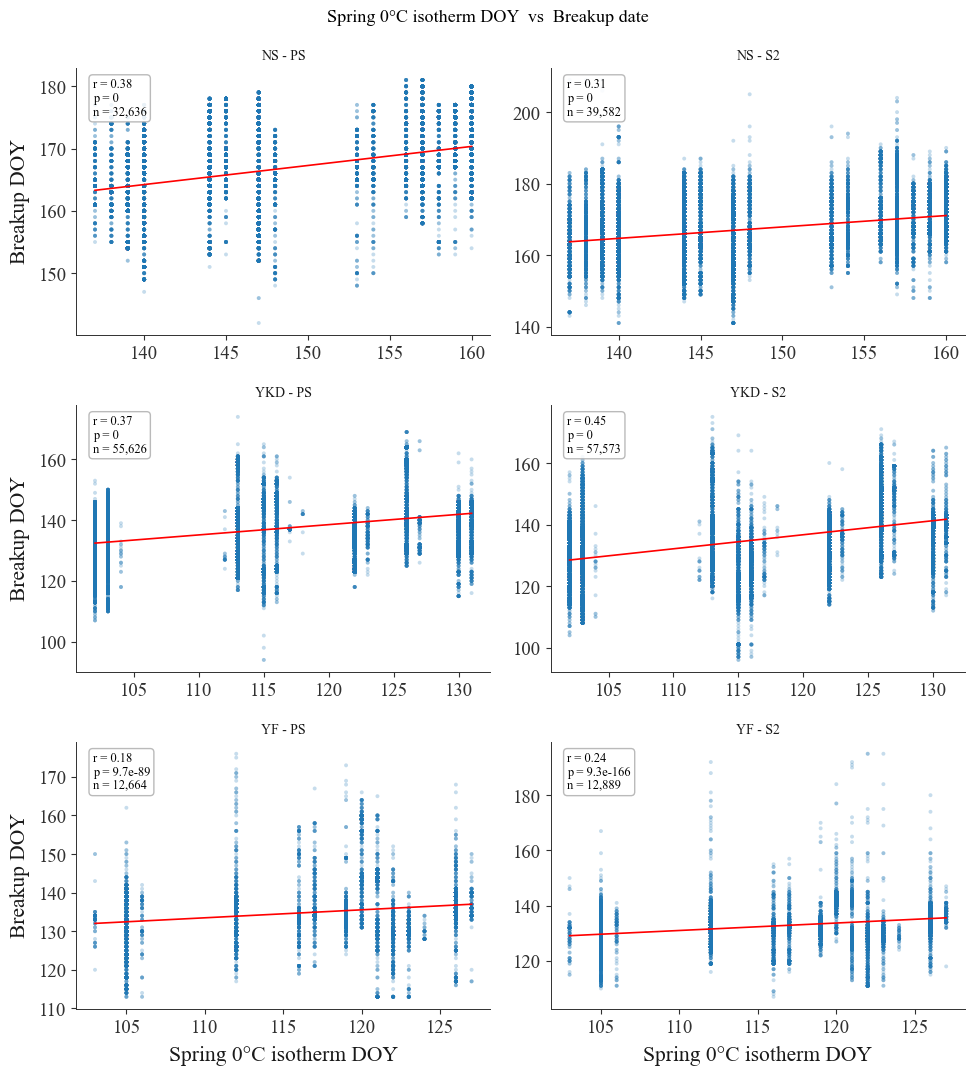

  plotting Autumn 0°C isotherm DOY x Freezeup...
    NS  PS: r=+0.06  p=7.6e-13  n=15,080
    NS  S2: r=+0.03  p=2.3e-05  n=14,732
    YKD  PS: r=-0.46  p=0  n=47,555
    YKD  S2: r=+0.07  p=2.2e-52  n=48,429
    YF  PS: r=+0.47  p=0  n=8,139
    YF  S2: r=+0.11  p=2.8e-32  n=11,734


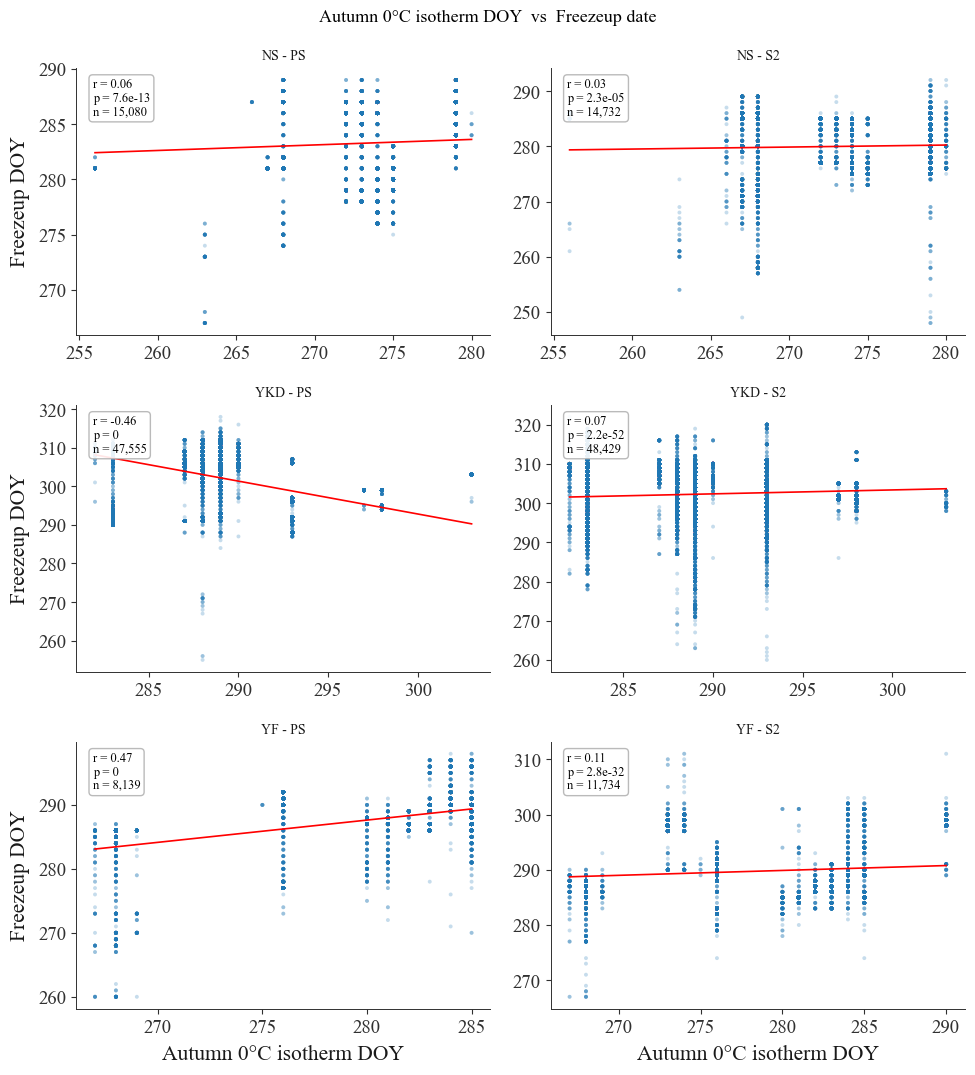

In [12]:
# ============================================================
# Cell 4 — Metric: Day of 0°C isotherm
# Breakup:  last DOY in Jan–Jun where 5-day running mean T2m < 0, +1
# Freezeup: first DOY in Aug–Dec where 5-day running mean T2m < 0
# To swap to a different definition (e.g., different smoothing window, different
# month bounds, raw daily values instead of running mean), edit compute_isotherm_doy.
# ============================================================

import time as _time

def compute_isotherm_doy(t2m_panel: pd.DataFrame, smooth: int = 30) -> pd.DataFrame:
    """Per (lake_id, year, site, season): DOY of 0°C isotherm crossing.
    Returns DataFrame [lake_id, year, site, season, isotherm_doy]."""
    chunks = []
    for (site, season), site_df in t2m_panel.groupby(["site", "season"]):
        t0 = _time.time()
        wide = (site_df.pivot_table(index="time", columns="lake_id", values="t2m_C")
                       .sort_index())
        smoothed = wide.rolling(smooth, center=True, min_periods=1).mean().values
        is_neg   = smoothed < 0
        lake_ids = wide.columns.values.astype(int)
        years    = wide.index.year.values
        months   = wide.index.month.values
        doys     = wide.index.dayofyear.values

        for year in np.unique(years):
            ymask = (years == year)
            if season == "Breakup":
                m = ymask & (months >= 1) & (months <= 6)
                if not m.any(): continue
                doy_when_neg = np.where(is_neg[m], doys[m, None], -1)
                last_neg = doy_when_neg.max(axis=0).astype(float)
                last_neg[last_neg == -1] = np.nan
                vals = last_neg + 1
            else:
                # DOY >= FREEZEUP_MIN_DOY (240) enforces the breakup/freezeup split:
                # any sub-240 DOY in the ERA5 panel belongs to breakup, not freezeup.
                m = ymask & (doys >= FREEZEUP_MIN_DOY) & (months <= 12)
                if not m.any(): continue
                doy_when_neg = np.where(is_neg[m], doys[m, None], 9999)
                first_neg = doy_when_neg.min(axis=0).astype(float)
                first_neg[first_neg == 9999] = np.nan
                vals = first_neg
            chunks.append(pd.DataFrame({
                "lake_id": lake_ids, "year": int(year),
                "site": site, "season": season, "isotherm_doy": vals,
            }))
        print(f"  [{site} {season}] {len(lake_ids):,} lakes × {len(np.unique(years))} years "
              f"({_time.time()-t0:.1f}s)", flush=True)
    return pd.concat(chunks, ignore_index=True).dropna(subset=["isotherm_doy"])

print("Computing 0°C isotherm DOY per lake-year...", flush=True)
isotherm_df = compute_isotherm_doy(t2m_daily, smooth=5)
print(f"  -> {len(isotherm_df):,} rows", flush=True)

print("Merging with phenology...", flush=True)
isotherm_merged = merge_with_phenology(isotherm_df, "isotherm_doy")
print(f"  -> {len(isotherm_merged):,} rows after join", flush=True)

plot_correlation_grid(isotherm_merged, "isotherm_doy",
                      "Spring 0°C isotherm DOY", "Breakup")
plot_correlation_grid(isotherm_merged, "isotherm_doy",
                      "Autumn 0°C isotherm DOY", "Freezeup")

Computing per-(site, season) 30-day pre-event windows...
  [NS Breakup] earliest event DOY = 141, window = DOY 111-140 (30 days, n_events=72,218)
  [NS Freezeup] earliest event DOY = 248, window = DOY 218-247 (30 days, n_events=29,812)
  [YF Breakup] earliest event DOY = 107, window = DOY 77-106 (30 days, n_events=25,553)
  [YF Freezeup] earliest event DOY = 260, window = DOY 230-259 (30 days, n_events=19,873)
  [YKD Breakup] earliest event DOY = 94, window = DOY 64-93 (30 days, n_events=113,255)
  [YKD Freezeup] earliest event DOY = 255, window = DOY 225-254 (30 days, n_events=96,018)

Computing degree days per lake-year over each window...
  [NS Breakup] window DOY 111-140: 39,858 (lake,year) pairs (1.5s)
  [NS Freezeup] window DOY 218-247: 39,858 (lake,year) pairs (1.5s)
  [YF Breakup] window DOY 77-106: 13,006 (lake,year) pairs (1.5s)
  [YF Freezeup] window DOY 230-259: 13,006 (lake,year) pairs (1.5s)
  [YKD Breakup] window DOY 64-93: 58,303 (lake,year) pairs (1.6s)
  [YKD Freezeup

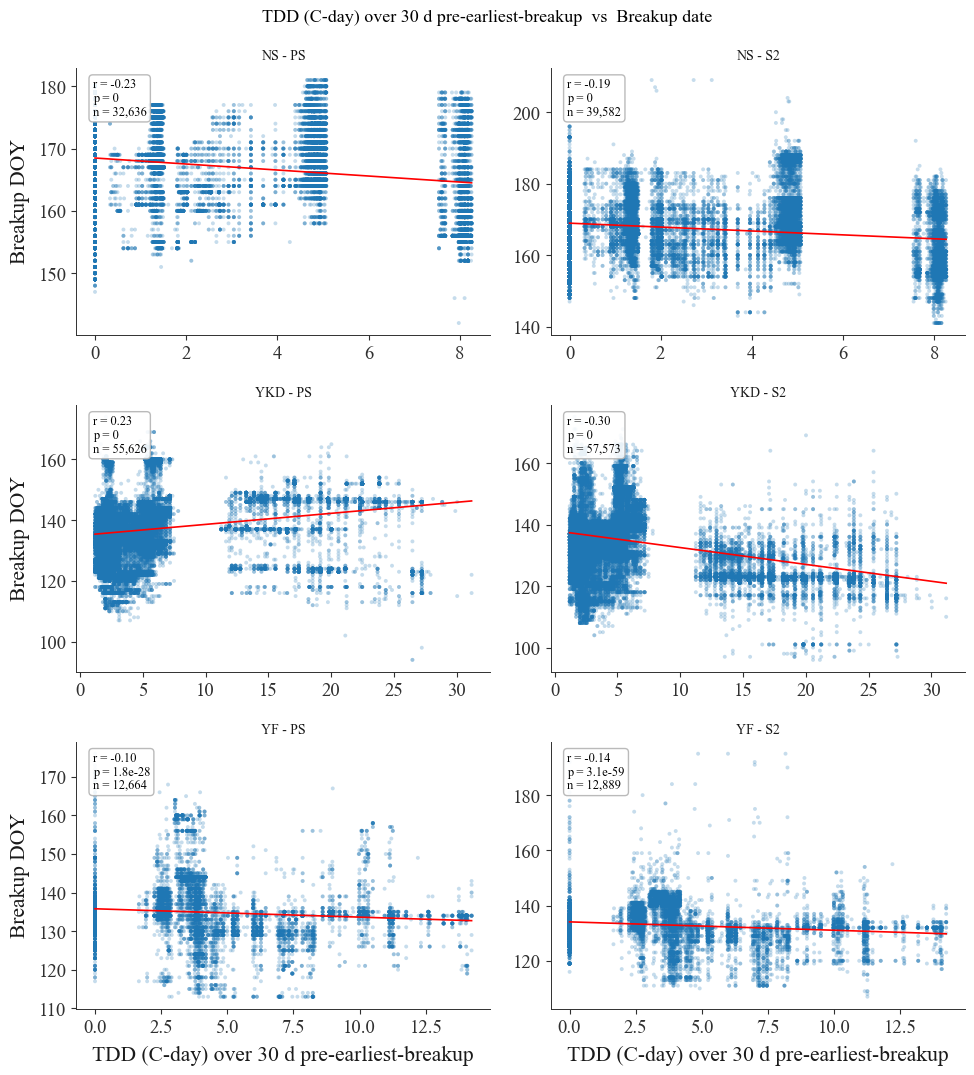

  plotting FDD (C-day) over 30 d pre-earliest-freezeup x Freezeup...
    NS  PS: fit failed (zero variance in predictor)
    NS  S2: fit failed (zero variance in predictor)
    YKD  PS: fit failed (zero variance in predictor)
    YKD  S2: fit failed (zero variance in predictor)
    YF  PS: fit failed (zero variance in predictor)
    YF  S2: fit failed (zero variance in predictor)


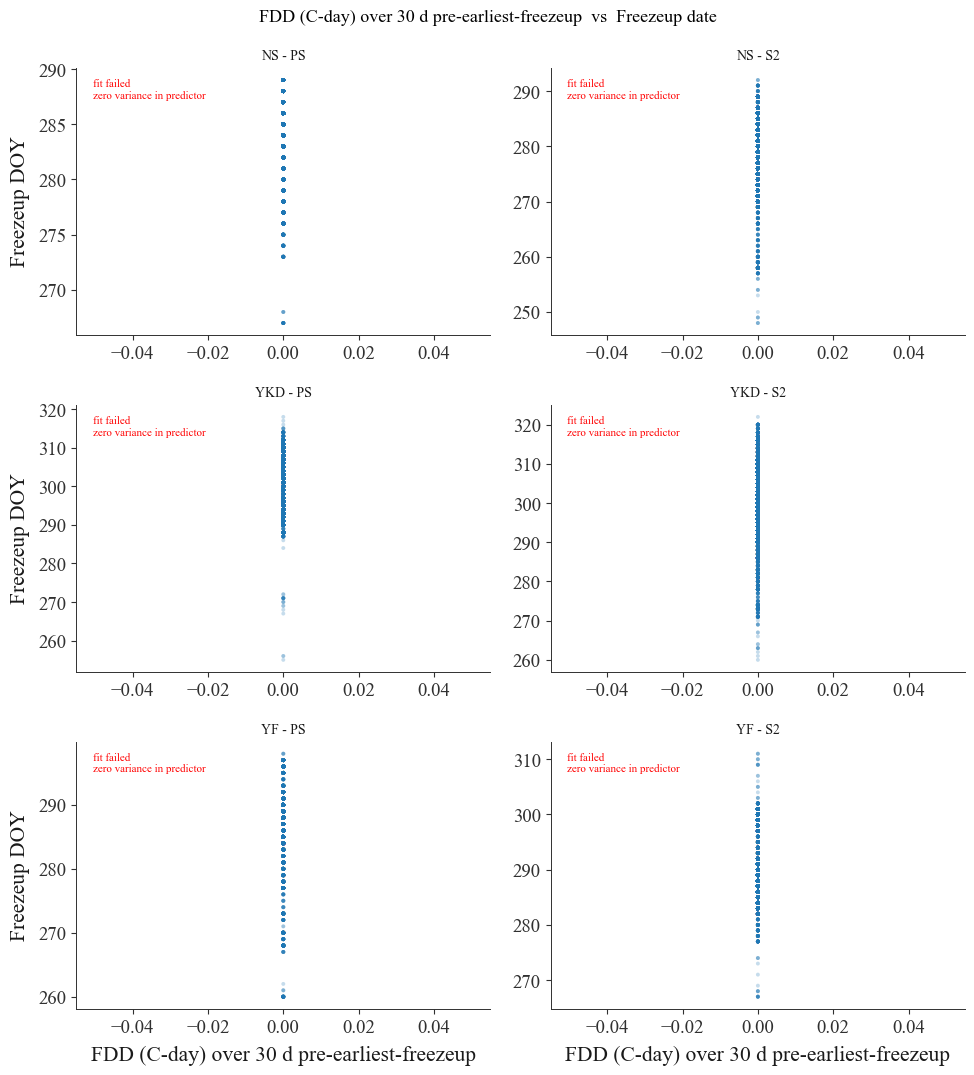

In [13]:
# ============================================================
# Cell 5 - Metric: Degree days over fixed 30-day pre-event window
# For each (site, season): a single 30-day DOY window ending one day before the
# earliest observed event date (across all years, lakes, both sensors). The
# window is identical for every (lake, year, sensor) within that site/season,
# so the metric is independent of the phenology dates being predicted.
# Breakup:  TDD = sum max(0,  daily T)  over the window.
# Freezeup: FDD = sum max(0, -daily T)  over the window.
# ============================================================

import time as _time

def compute_degree_days(t2m_panel: pd.DataFrame, windows: dict) -> pd.DataFrame:
    """TDD (breakup) or FDD (freezeup) summed over each (site, season) window.
    Uses every available daily row at the site regardless of which season-tagged
    panel it came from, so windows that straddle the Jul/Aug season boundary
    still pick up days stored under the other season's panel.
    Returns DataFrame [lake_id, year, site, season, degree_days]."""
    base = (t2m_panel.drop_duplicates(subset=["lake_id", "site", "time"]).copy())
    base["doy"]  = base["time"].dt.dayofyear
    base["year"] = base["time"].dt.year
    chunks = []
    for (site, season), (start_doy, end_doy) in windows.items():
        t0 = _time.time()
        df = base[(base["site"] == site) &
                  (base["doy"] >= start_doy) & (base["doy"] <= end_doy)].copy()
        sign = 1 if season == "Breakup" else -1
        df["dd"] = np.maximum(0.0, sign * df["t2m_C"])
        agg = (df.groupby(["lake_id", "year"])["dd"].sum()
                 .reset_index()
                 .rename(columns={"dd": "degree_days"}))
        agg["site"]   = site
        agg["season"] = season
        chunks.append(agg)
        print(f"  [{site} {season}] window DOY {start_doy}-{end_doy}: "
              f"{len(agg):,} (lake,year) pairs ({_time.time()-t0:.1f}s)", flush=True)
    return pd.concat(chunks, ignore_index=True)

print("Computing per-(site, season) 30-day pre-event windows...", flush=True)
event_windows = compute_event_windows(phenology, n_days=30)

print("\nComputing degree days per lake-year over each window...", flush=True)
dd_df = compute_degree_days(t2m_daily, event_windows)
print(f"  -> {len(dd_df):,} rows", flush=True)

print("Merging with phenology...", flush=True)
dd_merged = merge_with_phenology(dd_df, "degree_days")
print(f"  -> {len(dd_merged):,} rows after join", flush=True)
# Persist for the standalone figure cell in FIGURES_AND_STATS.ipynb
ISOTHERM_MERGED_PATH.parent.mkdir(parents=True, exist_ok=True)
(isotherm_merged[["lake_id", "year", "site", "sensor", "season",
                  "event_date", "event_doy", "isotherm_doy"]]
    .to_parquet(ISOTHERM_MERGED_PATH, index=False))
print(f"  saved -> {ISOTHERM_MERGED_PATH}", flush=True)

plot_correlation_grid(dd_merged, "degree_days",
                      "TDD (C-day) over 30 d pre-earliest-breakup", "Breakup")
plot_correlation_grid(dd_merged, "degree_days",
                      "FDD (C-day) over 30 d pre-earliest-freezeup", "Freezeup")


Computing mean T2m per lake-year over each window...
  [NS Breakup] window DOY 111-140: 39,858 (lake,year) pairs (1.6s)
  [NS Freezeup] window DOY 218-247: 39,858 (lake,year) pairs (1.6s)
  [YF Breakup] window DOY 77-106: 13,006 (lake,year) pairs (1.5s)
  [YF Freezeup] window DOY 230-259: 13,006 (lake,year) pairs (1.5s)
  [YKD Breakup] window DOY 64-93: 58,303 (lake,year) pairs (1.6s)
  [YKD Freezeup] window DOY 225-254: 58,303 (lake,year) pairs (1.6s)
  -> 222,334 rows
Merging with phenology...
  -> 356,639 rows after join
  plotting Mean T2m (C) over 30 d pre-earliest-breakup x Breakup...
    NS  PS: r=-0.27  p=0  n=32,636
    NS  S2: r=-0.14  p=3.6e-172  n=39,582
    YKD  PS: r=+0.17  p=0  n=55,626
    YKD  S2: r=-0.35  p=0  n=57,573
    YF  PS: r=+0.18  p=1.8e-93  n=12,664
    YF  S2: r=+0.14  p=2.2e-59  n=12,889


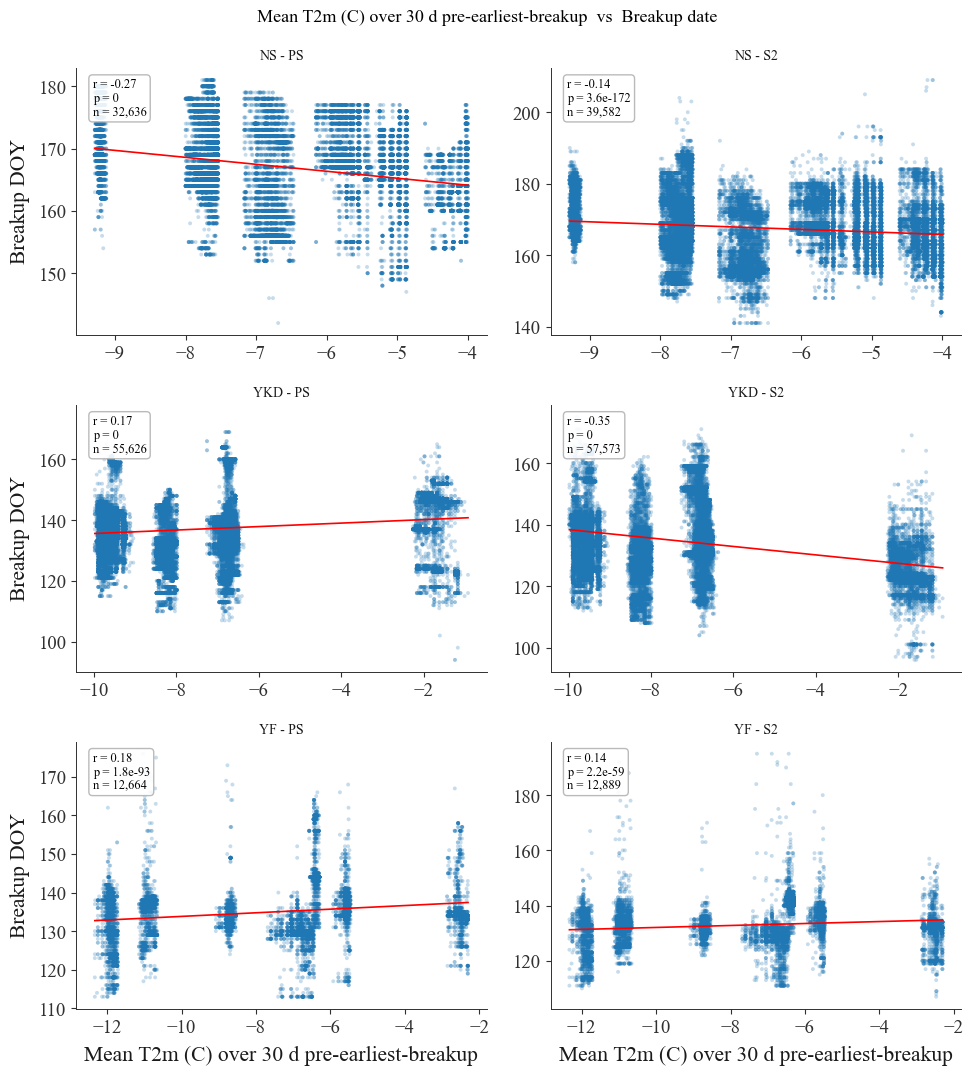

  plotting Mean T2m (C) over 30 d pre-earliest-freezeup x Freezeup...
    NS  PS: r=-0.24  p=3.6e-196  n=15,080
    NS  S2: r=-0.11  p=1.5e-38  n=14,732
    YKD  PS: r=+0.00  p=0.54  n=47,555
    YKD  S2: r=+0.24  p=0  n=48,429
    YF  PS: r=+0.45  p=0  n=8,139
    YF  S2: r=+0.57  p=0  n=11,734


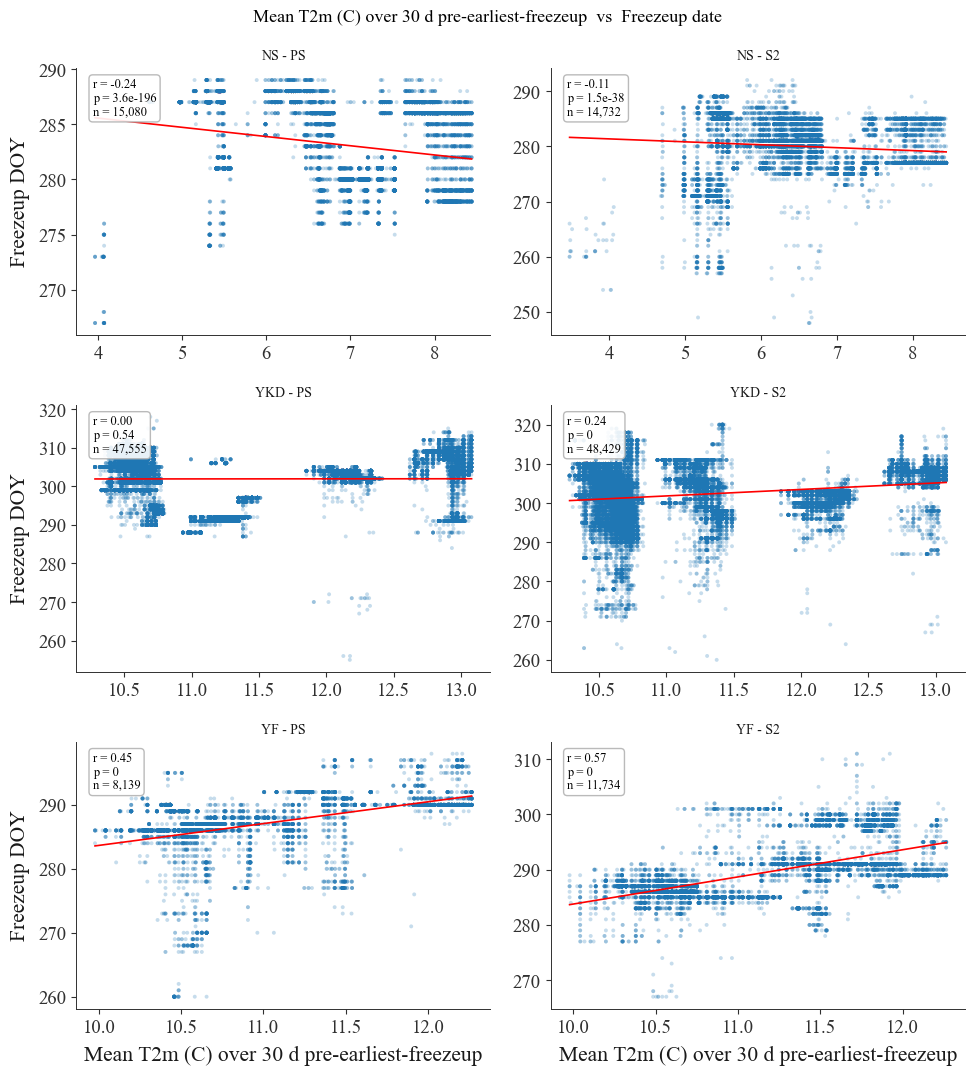

In [14]:
# ============================================================
# Cell 6 - Metric: Mean T2m over the same 30-day pre-event window used in Cell 5
# Same per-(site, season) window: 30 days ending one day before the earliest
# observed event date for that site/season across all years/lakes/sensors.
# ============================================================

import time as _time

def compute_window_mean_temp(t2m_panel: pd.DataFrame, windows: dict) -> pd.DataFrame:
    """Mean daily T2m over each (site, season) window per (lake, year).
    Returns DataFrame [lake_id, year, site, season, mean_temp]."""
    base = (t2m_panel.drop_duplicates(subset=["lake_id", "site", "time"]).copy())
    base["doy"]  = base["time"].dt.dayofyear
    base["year"] = base["time"].dt.year
    chunks = []
    for (site, season), (start_doy, end_doy) in windows.items():
        t0 = _time.time()
        df = base[(base["site"] == site) &
                  (base["doy"] >= start_doy) & (base["doy"] <= end_doy)]
        out = (df.groupby(["lake_id", "year"])["t2m_C"].mean()
                 .reset_index()
                 .rename(columns={"t2m_C": "mean_temp"}))
        out["site"]   = site
        out["season"] = season
        chunks.append(out)
        print(f"  [{site} {season}] window DOY {start_doy}-{end_doy}: "
              f"{len(out):,} (lake,year) pairs ({_time.time()-t0:.1f}s)", flush=True)
    return pd.concat(chunks, ignore_index=True)

# Reuses event_windows computed in the previous cell.
print("Computing mean T2m per lake-year over each window...", flush=True)
temp_df = compute_window_mean_temp(t2m_daily, event_windows)
print(f"  -> {len(temp_df):,} rows", flush=True)

print("Merging with phenology...", flush=True)
temp_merged = merge_with_phenology(temp_df, "mean_temp")
print(f"  -> {len(temp_merged):,} rows after join", flush=True)

plot_correlation_grid(temp_merged, "mean_temp",
                      "Mean T2m (C) over 30 d pre-earliest-breakup", "Breakup")
plot_correlation_grid(temp_merged, "mean_temp",
                      "Mean T2m (C) over 30 d pre-earliest-freezeup", "Freezeup")


  NS: 5,694 lakes  S=3,249  M=2,183  L=262
  YKD: 8,333 lakes  S=4,642  M=3,489  L=202
  YF: 1,858 lakes  S=916  M=897  L=45


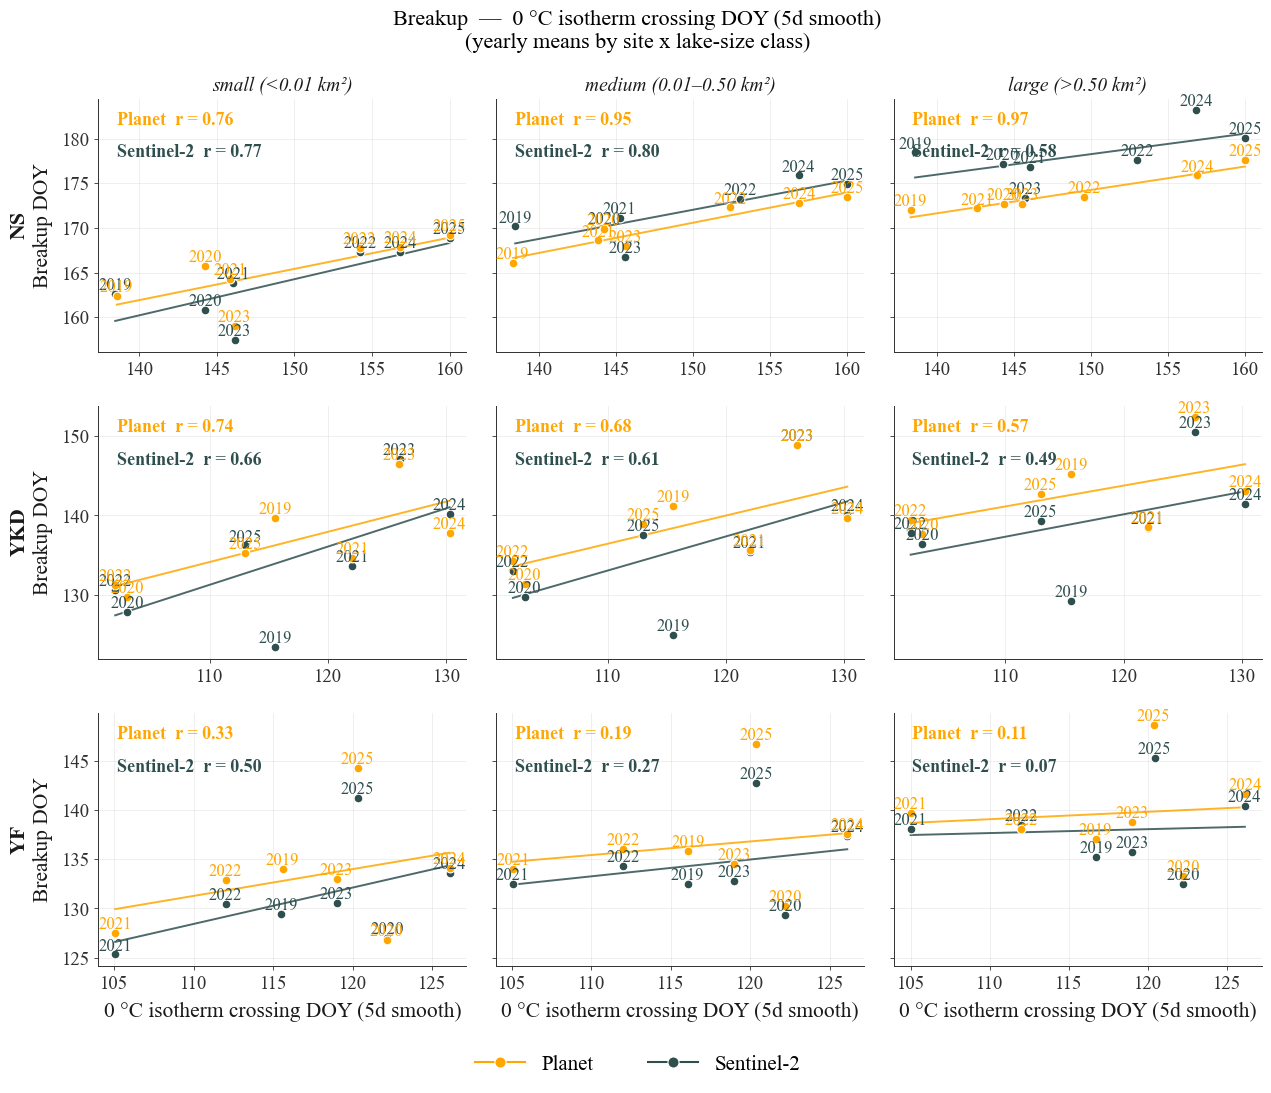

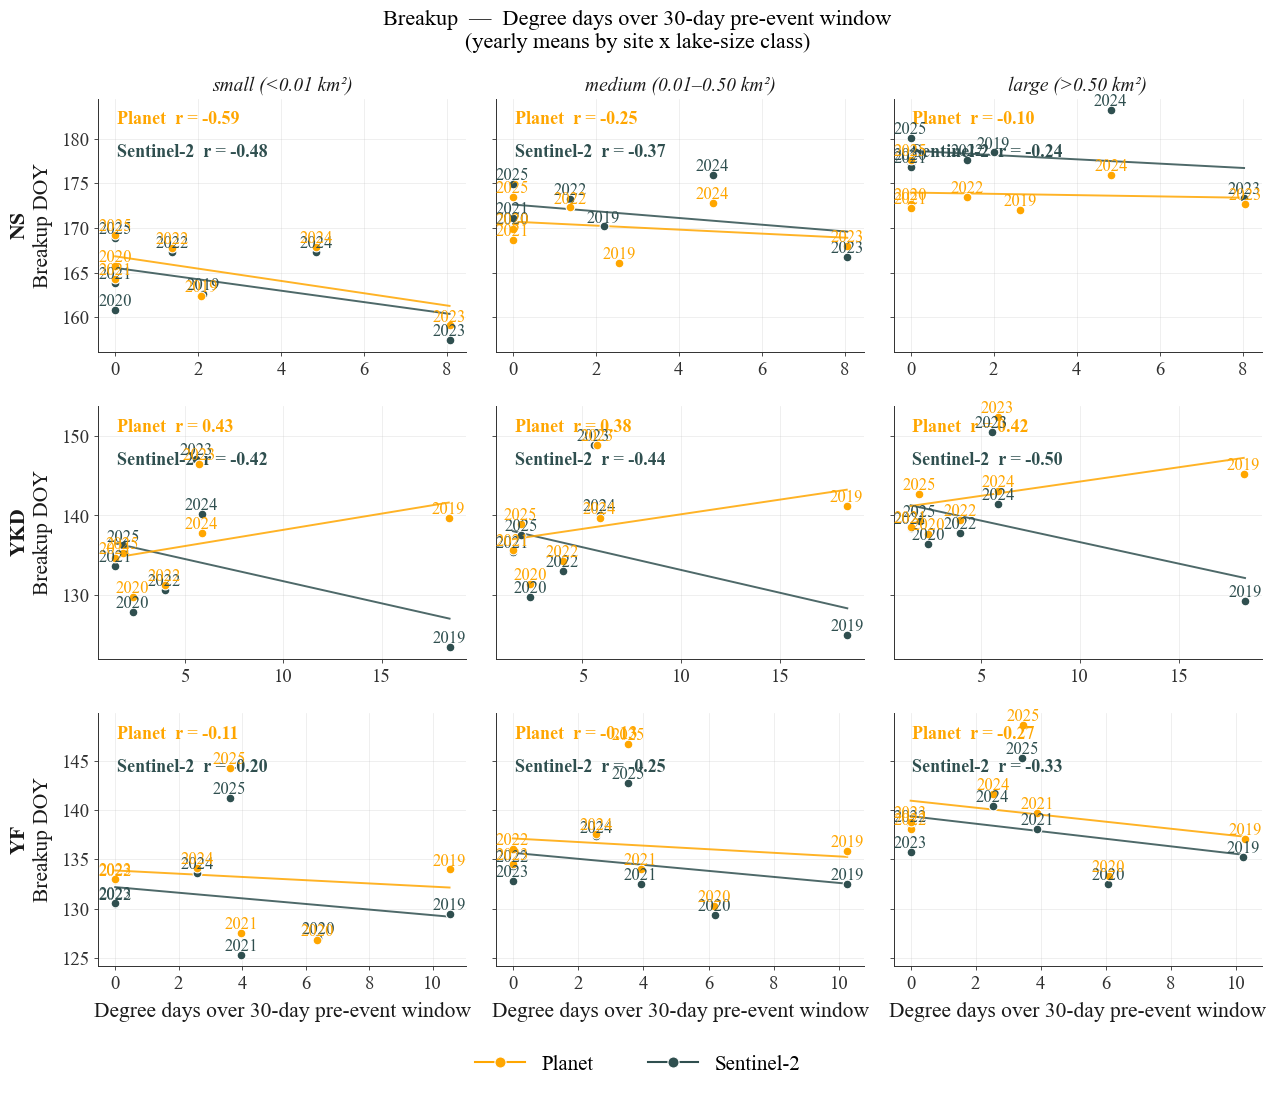

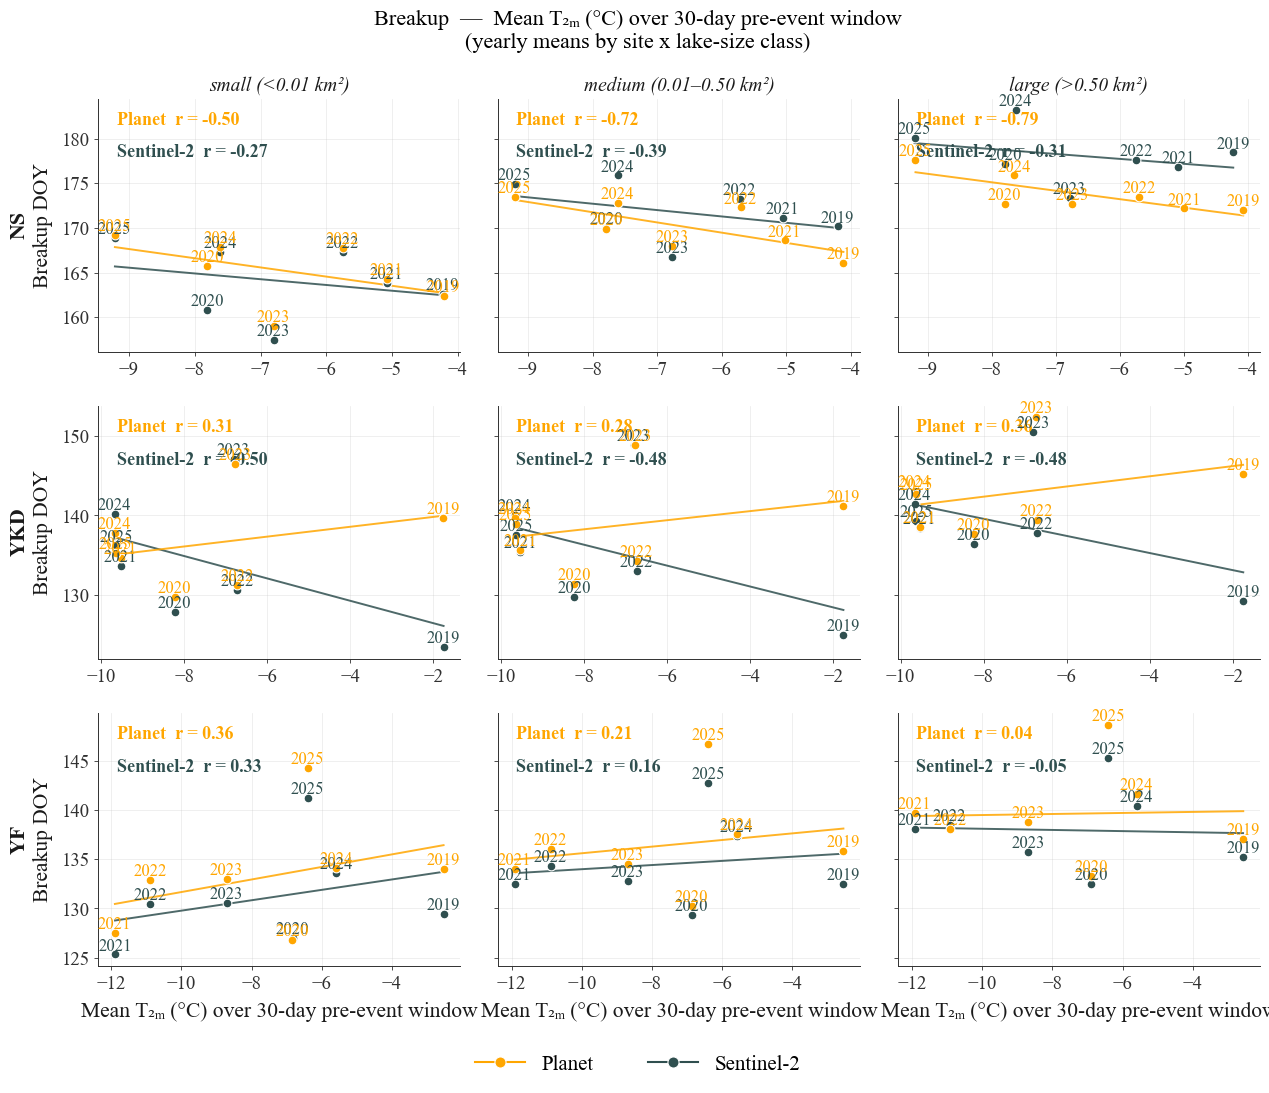

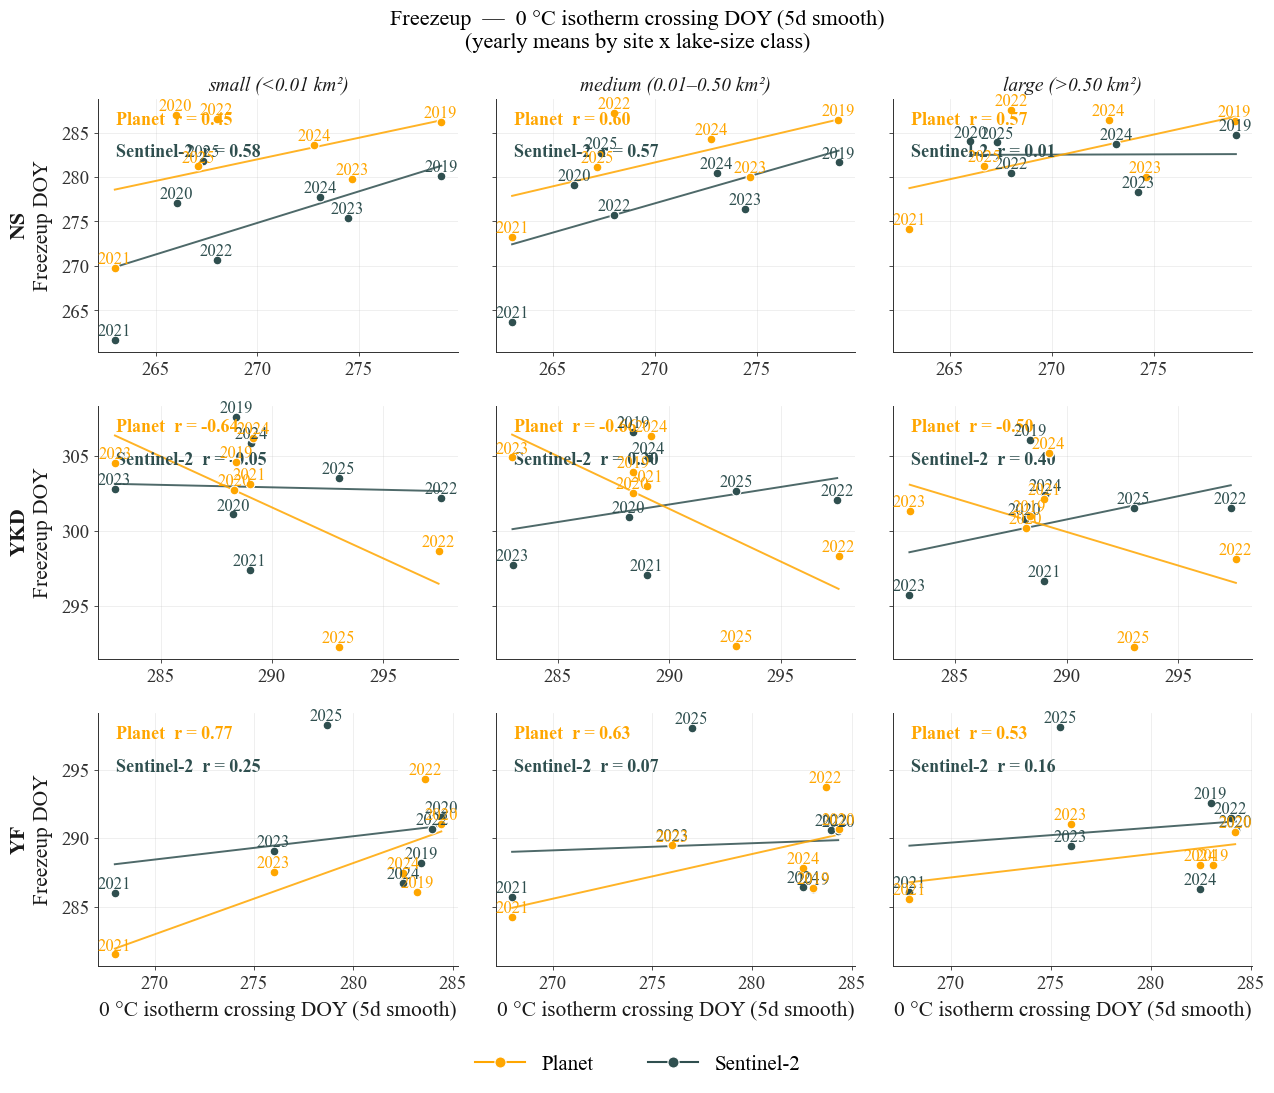

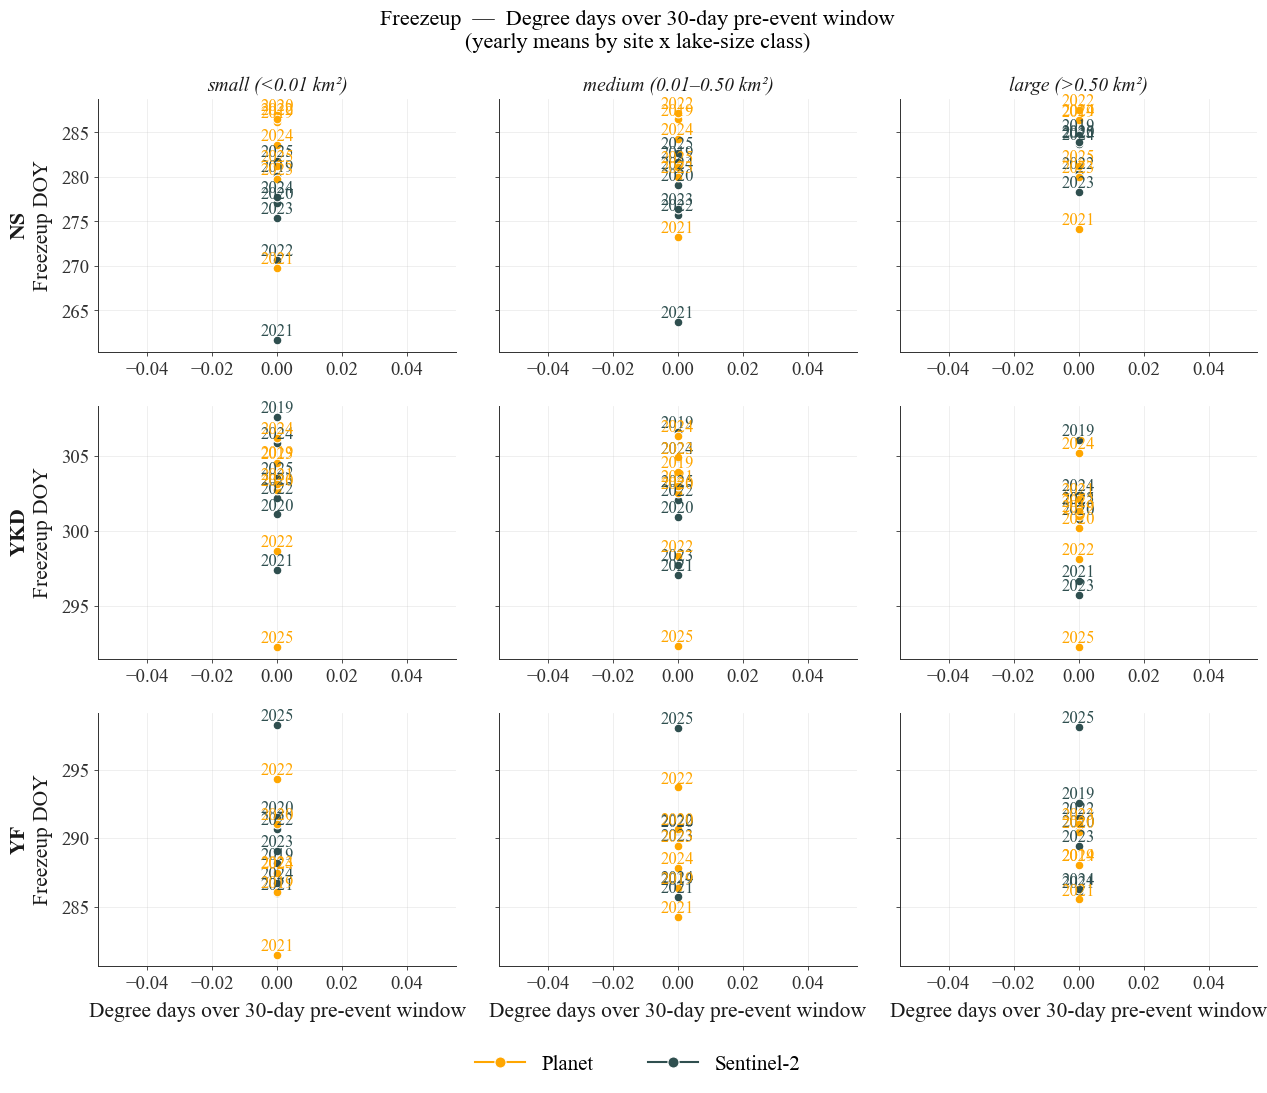

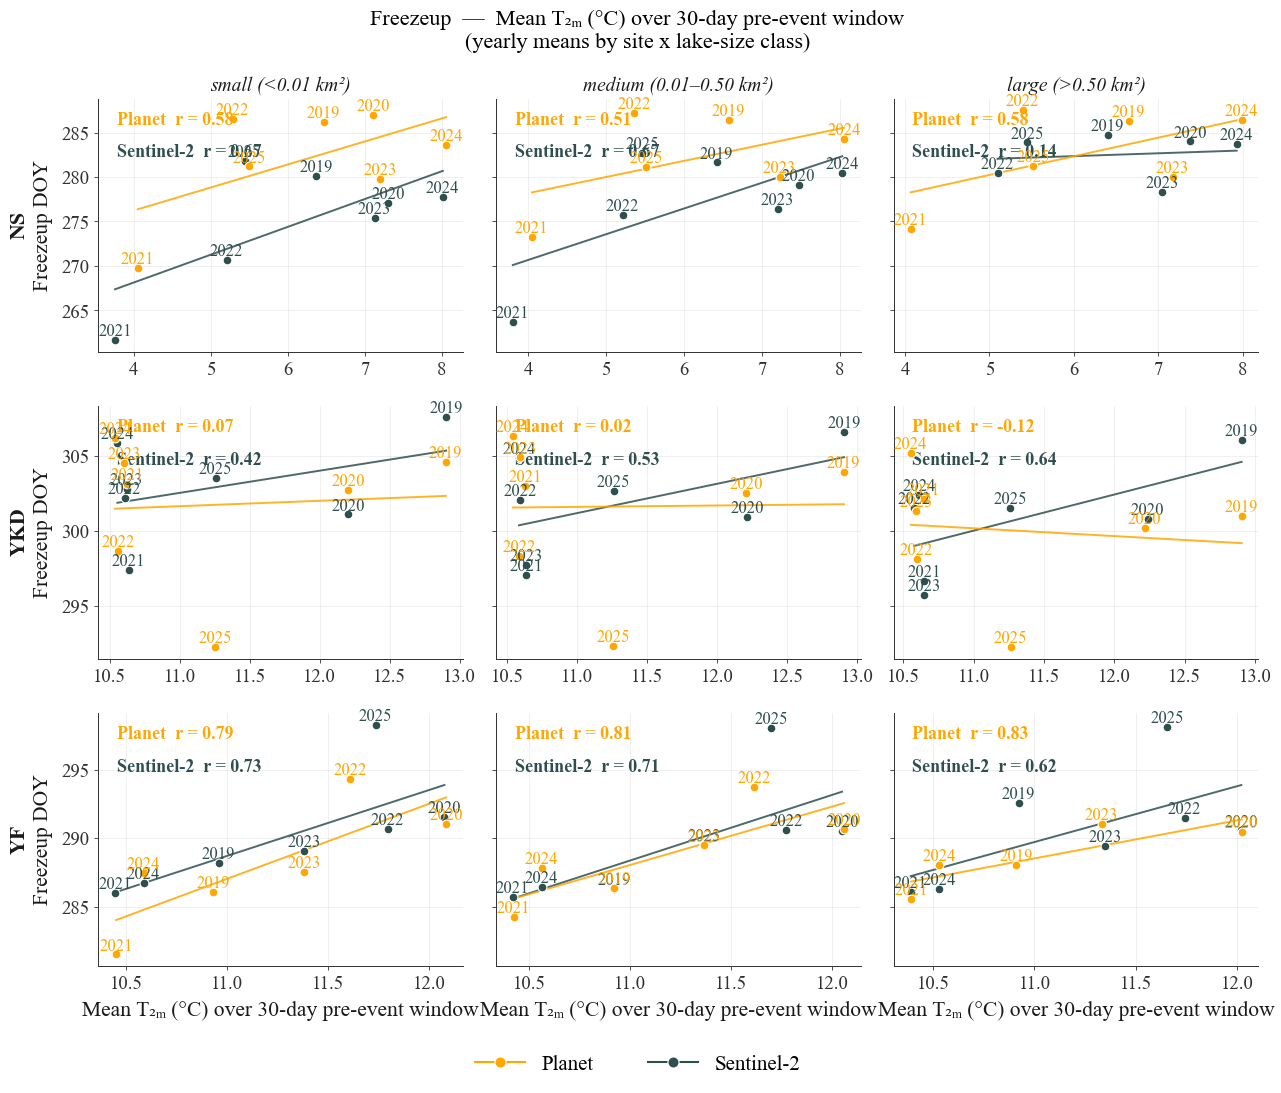

In [15]:
# ============================================================
# Cell 7 - Yearly-mean correlations: 3 sites x 3 lake-size classes x 3 metrics
# Planet (orange) and Sentinel-2 (dark) plotted as separate series with their
# own linear fits. Year labels, r/p/n stats, and layout match the original.
# ============================================================

import matplotlib.lines as mlines
from scipy.stats import pearsonr

PLANET_COLOR   = "#ffa600"
SENTINEL_COLOR = "#2f4f4f"
SENSOR_STYLE = {
    "PS": {"color": PLANET_COLOR,   "label": "Planet"},
    "S2": {"color": SENTINEL_COLOR, "label": "Sentinel-2"},
}

plt.rcParams.update({
    "font.family":       "Times New Roman",
    "mathtext.fontset":  "stix",
    "font.size":          15,        # +4
    "axes.titlesize":     16,        # +4
    "axes.labelsize":     15.5,      # +4
    "xtick.labelsize":    13.5,      # +4
    "ytick.labelsize":    13.5,      # +4
    "legend.fontsize":    15,        # +4
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.linewidth":      0.7,
    "axes.edgecolor":     "#303030",
    "xtick.color":        "#303030",
    "ytick.color":        "#303030",
    "axes.labelcolor":    "#1a1a1a",
    "axes.titlecolor":    "#1a1a1a",
    "axes.labelpad":       6,
    "figure.facecolor":   "white",
    "axes.facecolor":     "white",
})

_SIZE_BOUNDS = {"S": (0.0, 0.01), "M": (0.01, 0.5), "L": (0.5, float("inf"))}
_SIZE_LABELS = {"S": "small (<0.01 km²)",
                "M": "medium (0.01–0.50 km²)",
                "L": "large (>0.50 km²)"}
_SIZE_ORDER  = ["S", "M", "L"]

def _site_size_classes(lakes_gdf: gpd.GeoDataFrame) -> pd.DataFrame:
    g = lakes_gdf.to_crs(ALBERS_AK).copy()
    g["area_km2"]   = g.geometry.area / 1e6
    g["size_class"] = g["area_km2"].apply(
        lambda a: next(s for s, (lo, hi) in _SIZE_BOUNDS.items() if lo <= a < hi))
    return g[["lake_id", "area_km2", "size_class"]]

site_sizes = {site: _site_size_classes(lakes[site]) for site in SITES}
for site, df in site_sizes.items():
    counts = df["size_class"].value_counts().reindex(_SIZE_ORDER, fill_value=0)
    print(f"  {site}: {len(df):,} lakes  "
          + "  ".join(f"{s}={int(counts[s]):,}" for s in _SIZE_ORDER))

def _yearly_means(merged: pd.DataFrame, metric_col: str, site: str, season: str,
                  size: str, sensor: str, sizes: pd.DataFrame) -> pd.DataFrame:
    """Restrict to (site, season, size_class, sensor), then average per year."""
    sub = (merged[(merged["site"]   == site)
                  & (merged["season"] == season)
                  & (merged["sensor"] == sensor)]
           .merge(sizes[["lake_id", "size_class"]], on="lake_id"))
    sub = sub[sub["size_class"] == size]
    return sub.groupby("year")[[metric_col, "event_doy"]].mean().reset_index()

def plot_metric_3x3(merged: pd.DataFrame, metric_col: str,
                    metric_label: str, season: str) -> None:
    fig, axes = plt.subplots(len(SITES), len(_SIZE_ORDER),
                             figsize=(13, 11), sharey="row")
    for i, site in enumerate(SITES):
        sizes = site_sizes[site]
        for j, size in enumerate(_SIZE_ORDER):
            ax = axes[i, j]
            ax.grid(True, color="#bfbfbf", alpha=0.35, linewidth=0.5)
            ax.tick_params(length=3, width=0.6)

            for sensor in ("S2", "PS"):
                style = SENSOR_STYLE[sensor]
                yr = _yearly_means(merged, metric_col, site, season,
                                   size, sensor, sizes)
                if len(yr) < 2:
                    continue

                ax.scatter(yr[metric_col], yr["event_doy"], s=40,
                           color=style["color"], edgecolor="white",
                           linewidth=0.8, zorder=3)
                for _, row in yr.iterrows():
                    ax.text(row[metric_col], row["event_doy"], str(int(row["year"])),
                            fontsize=12, ha="center", va="bottom",   # +4
                            color=style["color"], zorder=4)

                if yr[metric_col].nunique() >= 2 and len(yr) >= 3:
                    try:
                        r, p = pearsonr(yr[metric_col], yr["event_doy"])
                        slope, intercept = np.polyfit(yr[metric_col],
                                                      yr["event_doy"], 1)
                        xs = np.linspace(yr[metric_col].min(),
                                         yr[metric_col].max(), 100)
                        ax.plot(xs, slope * xs + intercept,
                                color=style["color"], lw=1.4, alpha=0.85, zorder=2)
                        ypos = 0.95 if sensor == "PS" else 0.82
                        ax.text(0.05, ypos,
                                f"{style['label']}  r = {r:.2f}",
                                transform=ax.transAxes, va="top",
                                fontsize=13, fontweight="bold",   # +5, bold
                                color=style["color"])
                    except Exception as fit_err:
                        ax.text(0.05, 0.5, f"fit failed\n{fit_err}",
                                transform=ax.transAxes, va="top",
                                fontsize=12, color="red")          # +4

            if i == 0:
                ax.set_title(_SIZE_LABELS[size], fontsize=14, style="italic")  # +4
            if i == len(SITES) - 1:
                ax.set_xlabel(metric_label)
            if j == 0:
                ax.set_ylabel(f"$\\mathbf{{{site}}}$\n{season} DOY")  # bold site name

    handles = [mlines.Line2D([], [], marker="o", linestyle="-",
                             color=SENSOR_STYLE[s]["color"], markersize=8,
                             markeredgecolor="white", markeredgewidth=0.8,
                             label=SENSOR_STYLE[s]["label"])
               for s in ("PS", "S2")]
    fig.legend(handles=handles, loc="lower center",
               bbox_to_anchor=(0.5, -0.005), ncol=2, frameon=False,
               handlelength=2.4, columnspacing=2.6)
    fig.suptitle(f"{season}  —  {metric_label}\n(yearly means by site x lake-size class)",  # × → x
                 fontsize=16)                                                                 # +4
    fig.tight_layout(rect=[0, 0.04, 1, 1])
    plt.show()

# Reuse merged dataframes from Cells 4-6 (must be run first).
metrics = [
    (isotherm_merged, "isotherm_doy",  "0 °C isotherm crossing DOY (5d smooth)"),
    (dd_merged,       "degree_days",   "Degree days over 30-day pre-event window"),
    (temp_merged,     "mean_temp",     "Mean T₂ₘ (°C) over 30-day pre-event window"),
]
for season in SEASONS:
    for merged, col, label in metrics:
        plot_metric_3x3(merged, col, label, season)

In [16]:
# ============================================================
# Quick summary: mean / earliest / latest 0°C isotherm date per (site, season)
# Uses `isotherm_df` from Cell 4 (cols: lake_id, year, site, season, isotherm_doy).
# DOYs are converted to calendar dates using a non-leap reference year so
# Feb 29 doesn't shift labels. Mean is rounded to the nearest whole DOY.
# ============================================================

from datetime import datetime, timedelta

def doy_to_label(doy: float) -> str:
    """Convert a (possibly fractional) DOY to 'DOY N / Mon D' using 2023 as a
    non-leap reference. NaN -> '—'."""
    if pd.isna(doy):
        return "—"
    d = int(round(doy))
    date = datetime(2023, 1, 1) + timedelta(days=d - 1)
    return f"{d:>3} / {date.strftime('%b')} {date.day}"

summary = (
    isotherm_df
    .dropna(subset=["isotherm_doy"])
    .groupby(["site", "season"])["isotherm_doy"]
    .agg(mean="mean", earliest="min", latest="max", n="size")
    .reset_index()
)

print(f"{'Site':<5} {'Season':<10} {'Mean (DOY / date)':<22} "
      f"{'Earliest':<22} {'Latest':<22} {'n':>10}")
print("-" * 95)
for _, r in summary.iterrows():
    print(f"{r['site']:<5} {r['season']:<10} "
          f"{doy_to_label(r['mean']):<22} "
          f"{doy_to_label(r['earliest']):<22} "
          f"{doy_to_label(r['latest']):<22} "
          f"{int(r['n']):>10,}")

Site  Season     Mean (DOY / date)      Earliest               Latest                          n
-----------------------------------------------------------------------------------------------
NS    Breakup    149 / May 29           137 / May 17           160 / Jun 9                39,858
NS    Freezeup   270 / Sep 27           256 / Sep 13           280 / Oct 7                39,858
YF    Breakup    117 / Apr 27           103 / Apr 13           127 / May 7                13,006
YF    Freezeup   279 / Oct 6            267 / Sep 24           290 / Oct 17               13,006
YKD   Breakup    116 / Apr 26           102 / Apr 12           131 / May 11               58,303
YKD   Freezeup   290 / Oct 17           282 / Oct 9            303 / Oct 30               58,303
